# ARMA processes

$(X_t)_{t\in \mathbb{Z}}$ is an ARMA($p, q$) process if it satisfies

$$ X_t - \phi_1 X_{t-1} - \cdots - \phi_p X_{t-p} = \epsilon_t + \theta_1 \epsilon_{t-1} + \cdots + \theta_q \epsilon_{t-q}, \qquad \epsilon_t \sim \mathrm{WN}(0, \sigma^2)$$

Under certain conditions on the AR coefficients $\phi_1, \ldots, \phi_p$, there exists a solution $X_t$ which is stationary and can be written as an (infinite) linear combination of $\epsilon_{t-j}$ with $j\ge 0$ (causal). We will mostly restrict attention to stationary and causal processes.

As an example, we plot the parameter restrictions on $\phi_1, \phi_2$ for which any ARMA(2, $q$) model has a stationary causal solution:

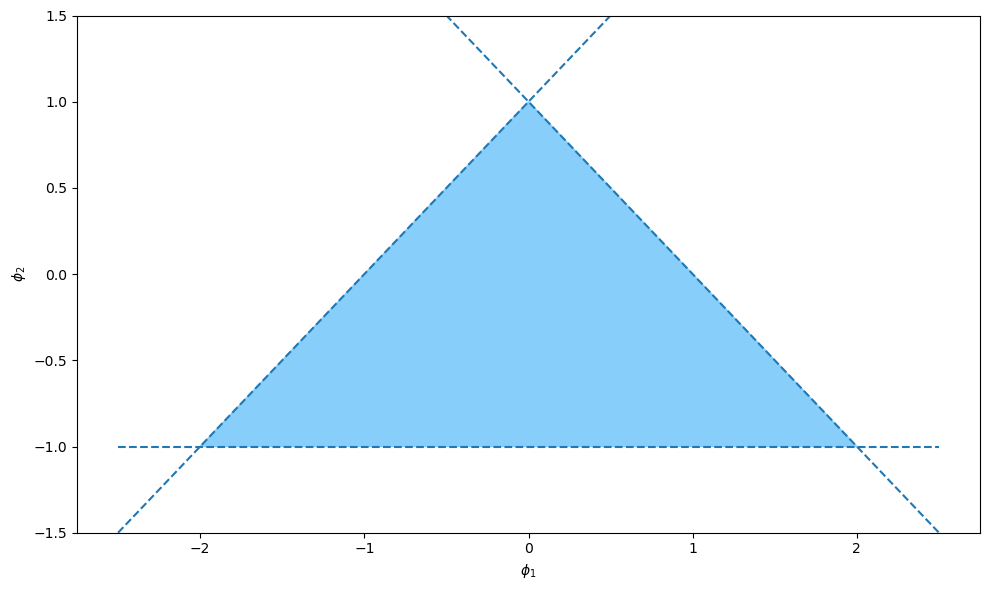

In [1]:
import math as mth
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

phi1 = np.linspace(-2.5, 2.5, 51)

fig, ax = plt.subplots(figsize = (10, 6))
ax.plot(phi1, 1 - phi1, color = "tab:blue", linestyle = "--")
ax.plot(phi1, 1 + phi1, color = "tab:blue", linestyle = "--")
ax.hlines(-1, -2.5, 2.5, color = "tab:blue", linestyle = "--")
ax.fill([-2, 0, 2], [-1, 1, -1], color = "lightskyblue")
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel(r"$\phi_1$")
ax.set_ylabel(r"$\phi_2$")
fig.tight_layout()
plt.show()


ARMA($p, q$) models of this type provide a rich class of models for stationary (univariate) time series. They are not suitable to model every stationary time series, but do include time series with a rich variety of, for example, autocovariance functions.

Some examples of the ACF and PACF of ARMA($p, q$) processes are given below.

In [4]:
def plot_ts(X, figsize = (12, 3)):
    n = len(X)
    fig, ax = plt.subplots(figsize = figsize)
    ax.plot(range(n), X)
    ax.set_xlabel(r"$t$")
    ax.set_ylabel(r"$X_t$")
    fig.tight_layout()
    plt.show()
    

def plot_acf_pacf(arma, nlags = 20, figsize = (12, 6)):

    fig, axes = plt.subplots(2, 1, figsize = figsize)
    x = range(nlags)
    acf = arma.acf(nlags)
    pacf = arma.pacf(nlags)
    titles = ["ACF", "PACF"]
    for (i, cf) in enumerate([acf, pacf]):
        axes[i].scatter(x, cf)
        axes[i].vlines(x, 0, cf, color = "tab:blue")
        axes[i].hlines(0, 0, nlags, color = "lightskyblue", alpha  =0.5)
        axes[i].set_xlim(-0.5, nlags + 0.5)
        axes[i].set_title(titles[i])
        axes[i].set_xticks([i * 4 for i in range(mth.floor(nlags/4) + 1)])
    
    fig.tight_layout()
    plt.show()

In [5]:
n = 400
burnin = 400

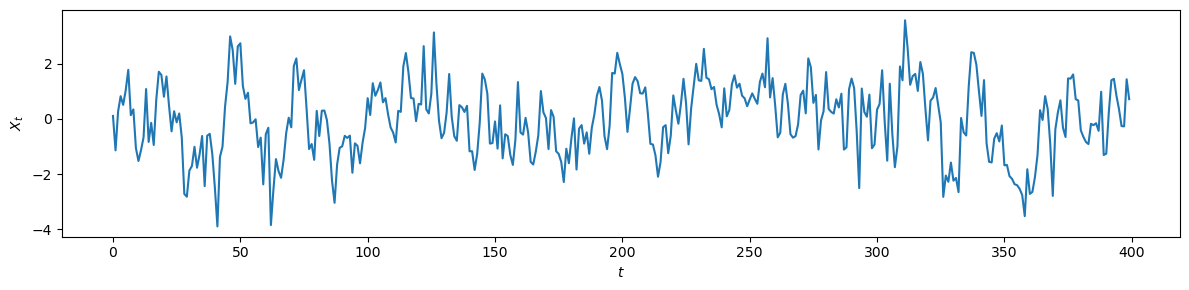

In [4]:
# AR(1), \phi = [0.7]

ar1 = sm.tsa.ArmaProcess(ar = [1.0, -0.7], ma = [1.0])
X = ar1.generate_sample(n + burnin)
plot_ts(X[burnin:])


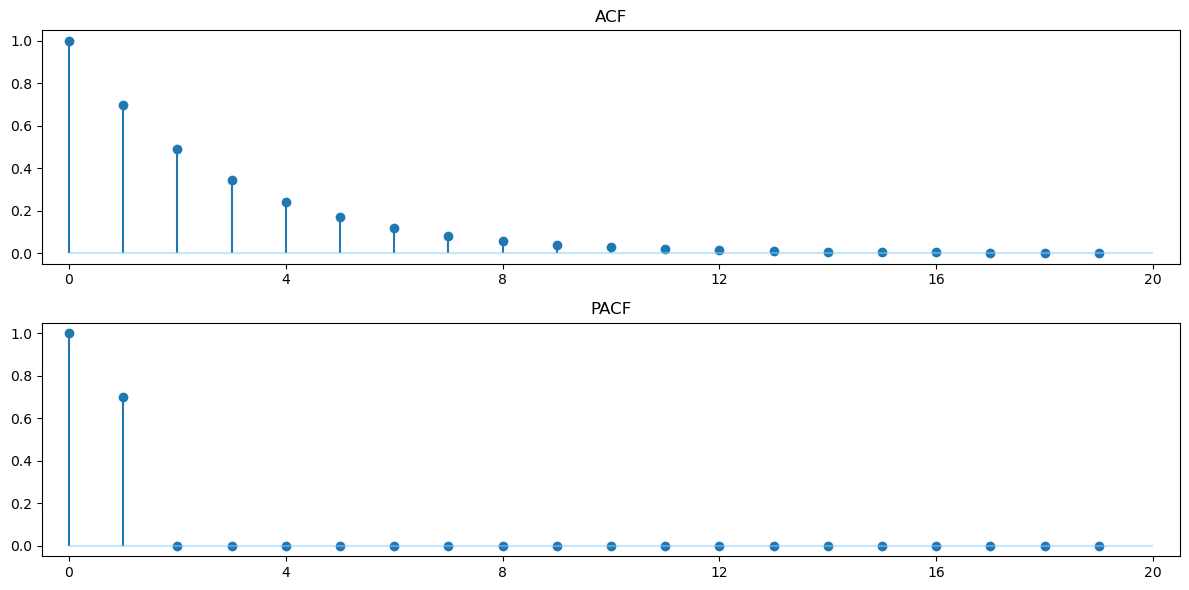

In [5]:
plot_acf_pacf(ar1)

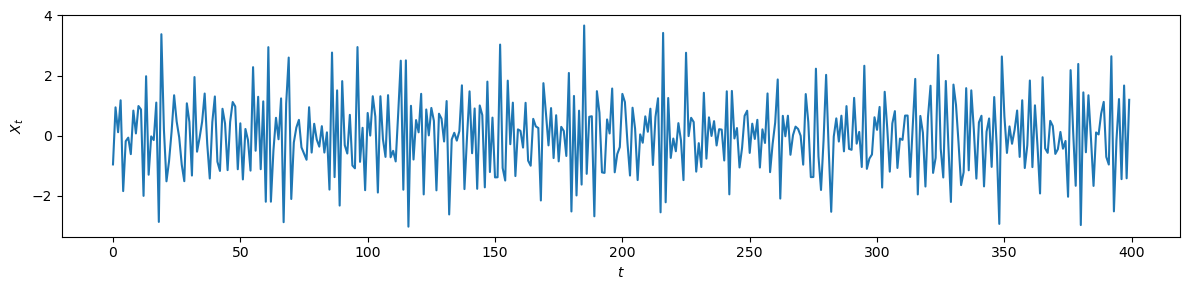

In [6]:
# MA(1), theta = [-0.8]
ma1 = sm.tsa.ArmaProcess(ar = [1.0], ma = [1.0, -0.8])
X = ma1.generate_sample(n + burnin)
plot_ts(X[burnin:])

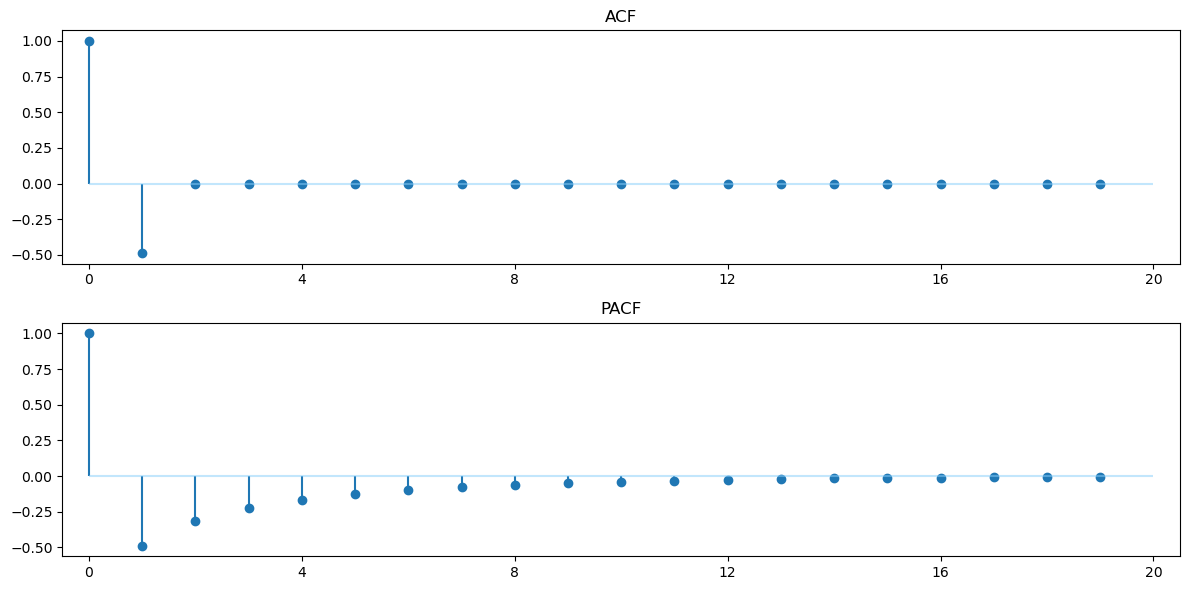

In [7]:
plot_acf_pacf(ma1)

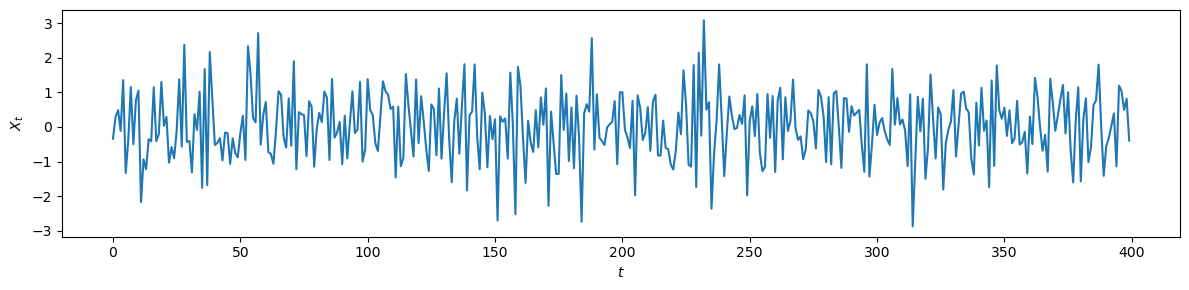

In [28]:
# ARMA(1, 1), \phi = [0.7], \theta = [-0.8]

arma11 = sm.tsa.ArmaProcess(ar = [1.0, -0.7], ma = [1.0, -0.8])
X = arma11.generate_sample(n + burnin)
plot_ts(X[burnin:])

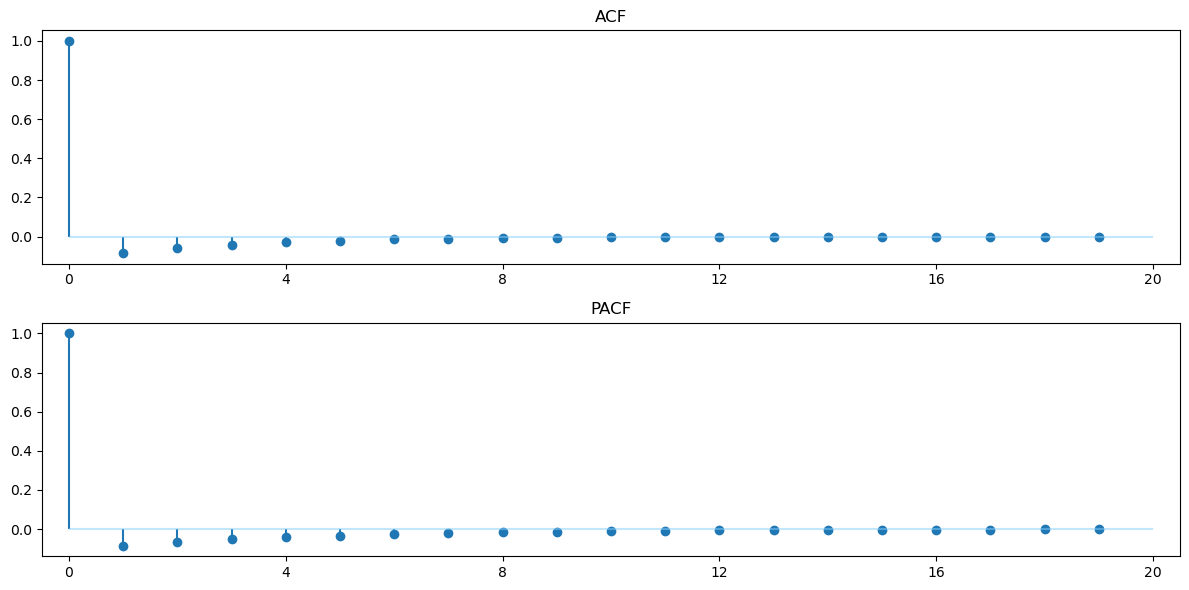

In [29]:
plot_acf_pacf(arma11, 20)

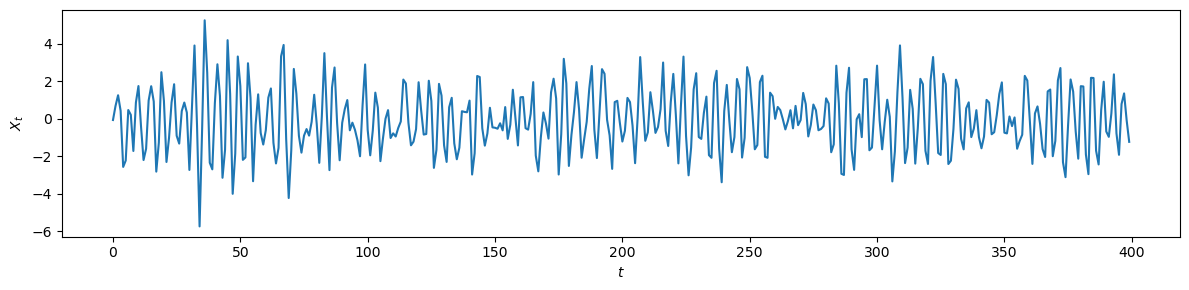

In [10]:
# AR(3), \phi = [0.3, -0.8, 0.1]

ar3 = sm.tsa.ArmaProcess(ar = [1.0, -0.3, 0.8, -0.1], ma = [1.0])
X = ar3.generate_sample(n + burnin)
plot_ts(X[burnin:])

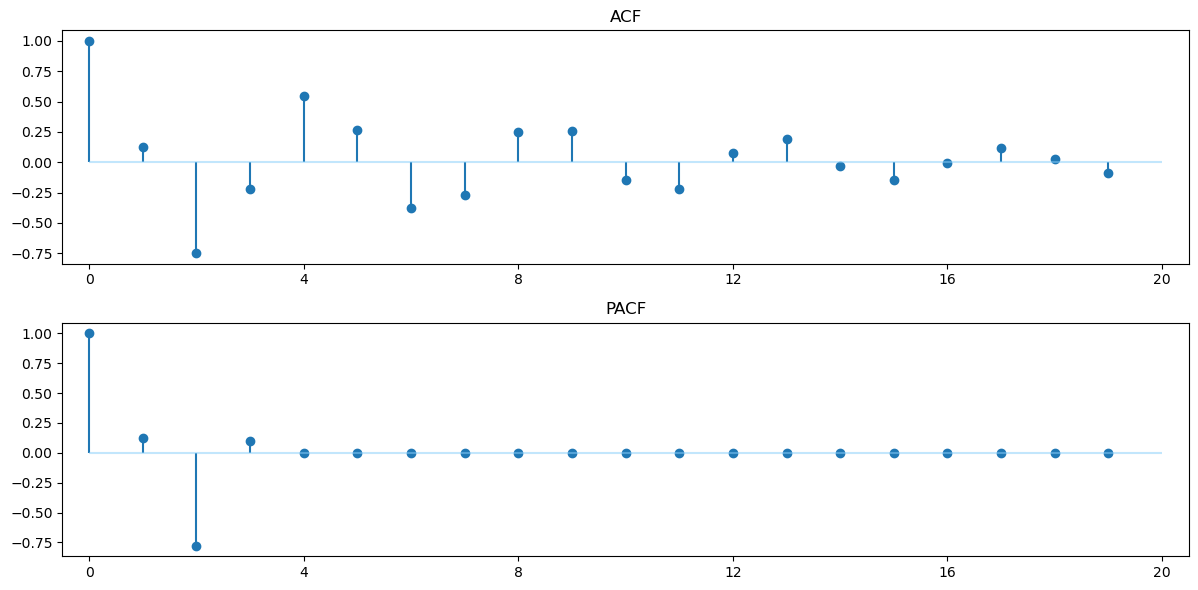

In [11]:
plot_acf_pacf(ar3, 20)

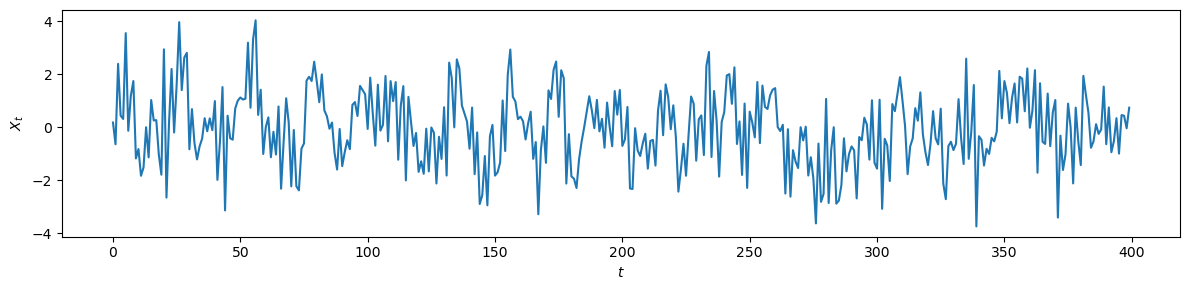

In [12]:
# MA(3), \theta = [0.2, 0.5, 0.8]

ma3 = sm.tsa.ArmaProcess(ar = [1.0], ma = [1.0, 0.2, 0.5, 0.8])
X = ma3.generate_sample(n + burnin)
plot_ts(X[burnin:])

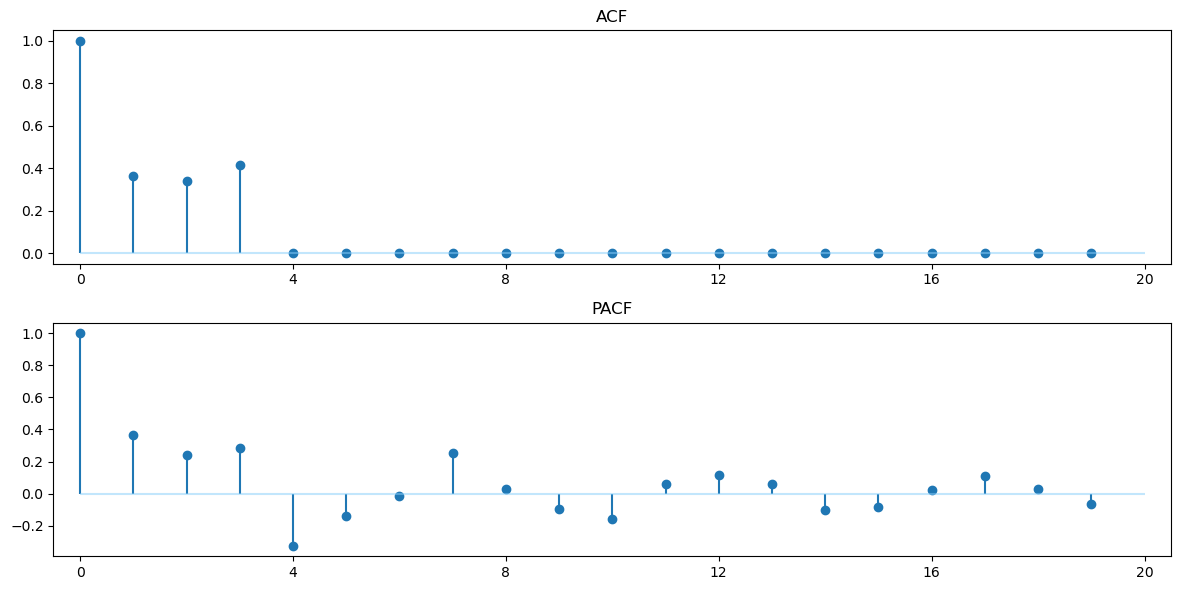

In [13]:
plot_acf_pacf(ma3, 20)


In [6]:
# ARMA(3, 3), phi = [0.3, -0.8, 0.1], \theta = [0.2, 0.5, 0.8]

arma33 = sm.tsa.ArmaProcess(ar = [1.0, -0.3, 0.8, -0.1], ma = [1.0, 0.2, 0.5, 0.8])
X = arma33.generate_sample(n + burnin)
# plot_ts(X[burnin:])

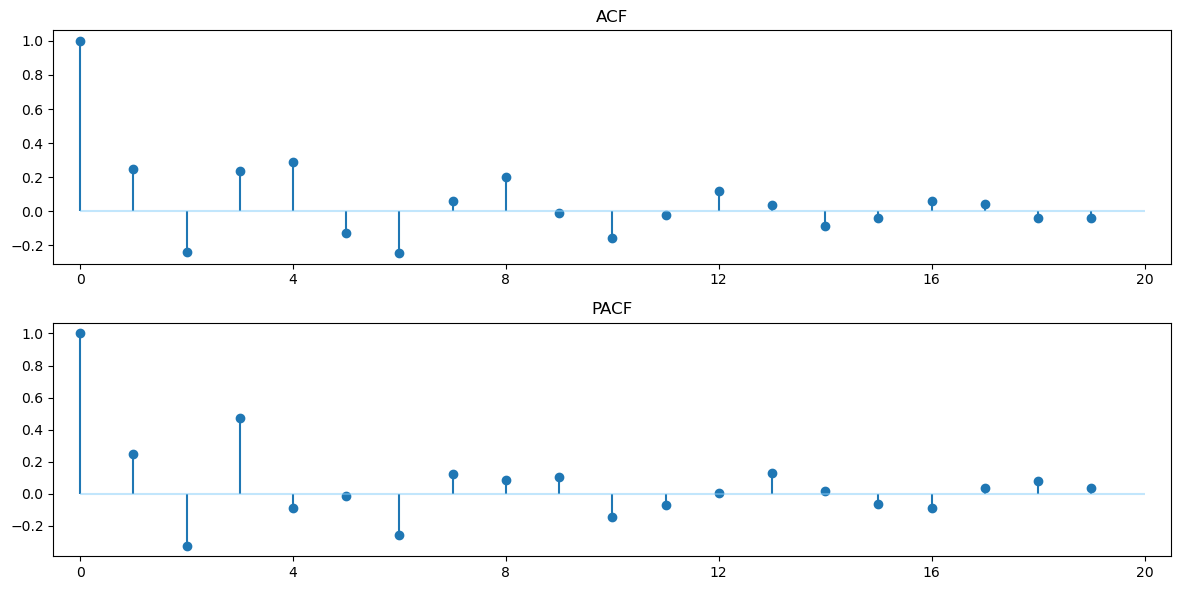

In [15]:
plot_acf_pacf(arma33)

Once we have an ARMA($p, q$) model it is also easy to forecast future values of the time series. 

Below we draw a realisation from the previous ARMA($3, 3$) model and forecast the next value based on based on the estimated autocovariances.

In [7]:
np.random.seed(1561)
burn_in = 400
n = 400

X = arma33.generate_sample(burn_in + n)
X = X[burn_in:burn_in+n]

m = 6
acvf = sm.tsa.acovf(X, nlag = m)
theta, sigma2 = sm.tsa.stattools.innovations_algo(acvf, n)
u = sm.tsa.stattools.innovations_filter(X, theta)
X_fcst_est = np.dot(theta[n-1, :], u[::-1][0:m])
X_fcst_est

0.7001856095578526

In [8]:
# A typically more convenient method: fit an ARMA model and use the forecast method
res = sm.tsa.ARIMA(X, order=(3,0,3)).fit(method="innovations_mle")
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  400
Model:                 ARIMA(3, 0, 3)   Log Likelihood                -592.203
Date:                Wed, 12 Nov 2025   AIC                           1200.406
Time:                        11:45:22   BIC                           1232.338
Sample:                             0   HQIC                          1213.051
                                - 400                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0233      0.109      0.215      0.830      -0.189       0.236
ar.L1          0.3373      0.055      6.160      0.000       0.230       0.445
ar.L2         -0.7260      0.039    -18.670      0.000      -0.802      -0.650
ar.L3          0.1322      0.055      2.408      0.016       0.025       0.240
ma.L1          0.2226      0.468      0.475      0.635      -0.695       1.140
ma.L2          0.4930      1.146      0.430      0.667      -1.753       2.739
ma.L3          0.8318      1.284      0.648      0.517      -1.686       3.349
sigma2         1.1040      1.694      0.652      0.515      -2.216       4.424
===================================================================================
Ljung-Box (L1) (Q):                   0.03   Jarque-Bera (JB):                 0.32
Prob(Q):                              0.87   Prob(JB):                         0.85
Heteroskedasticity (H):               0.90   Skew:                            -0.04
Prob(H) (two-sided):                  0.53   Kurtosis:                         3.11
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

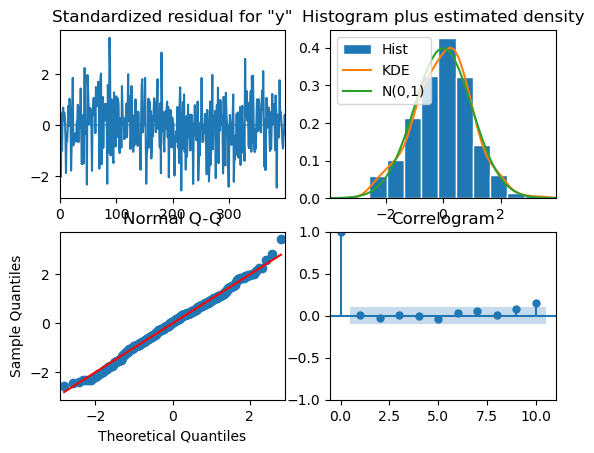

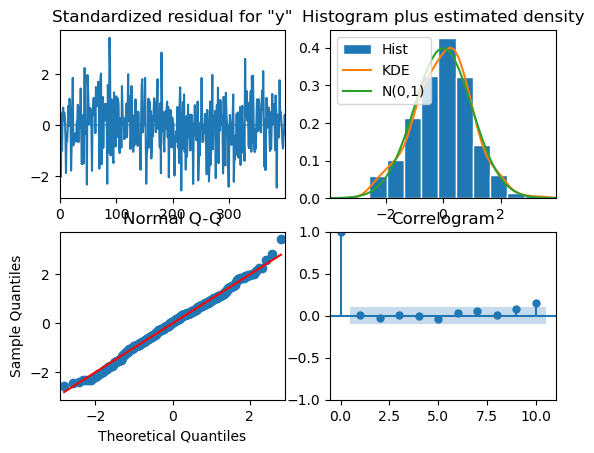

In [9]:
res.plot_diagnostics()

In [18]:
res.forecast(steps=6)


array([ 0.57391614,  0.25091306,  0.0870459 , -0.28970388, -0.27672371,
        0.02262284])

# ARMA lag order selection & estimation

As seen in the plots above, for AR and MA models, the ACF and PACF plots can reveal appropriate choices for the lag orders (i.e. $p$ and $q$).

The plots above were theoretical ACF and PACF plots. The ACF and PACF can also be estimated given a time series. This is demonstrated below using an example time series of Norwegian GDP growth 

In [13]:
import pandas as pd

In [27]:
# qdf = pd.read_csv(
#     # "https://ec.europa.eu/eurostat/estat-navtree-portlet-prod/BulkDownloadListing?file=data/namq_10_gdp.tsv.gz",
#     "estat_namq_10_gdp.tsv.gz",
#      sep=r'\,|\t',
#      engine='python'
# )

qdf.rename(
    columns={'geo\TIME_PERIOD':'geo'}
    ).query(
        "s_adj == 'SCA' & geo == 'NO' & (unit == 'CLV15_MNAC' | unit == 'CLV_PCH_SM') & na_item == 'B1GQ'"
        ).drop(
            ["s_adj", "na_item", "geo"],
             axis=1
             )

,freq,unit,1975-Q1,1975-Q2,1975-Q3,1975-Q4,1976-Q1,1976-Q2,1976-Q3,1976-Q4,...,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3
11757,Q,CLV15_MNAC,:,:,:,:,:,:,:,:,...,871440.2,865781.2,888517.3,892139.1,906674.3,894284.4,886642.8,887125.6,894533.1,:
27823,Q,CLV_PCH_SM,:,:,:,:,:,:,:,:,...,0.2,-3.0,1.2,1.3,4.0,3.3,-0.2,-0.6,-1.3,:


In [156]:
qdf = pd.read_csv(
    "estat_namq_10_gdp.tsv.gz",
     sep=r'\,|\t',
     engine='python'
).rename(
    columns={'geo\TIME_PERIOD':'geo'}
    ).query(
        "s_adj == 'SCA' & geo == 'NO' & (unit == 'CLV15_MNAC' | unit == 'CLV_PCH_SM') & na_item == 'B1GQ'"
        ).drop(
            ["s_adj", "na_item", "geo"],
             axis=1
             )

qdf = pd.melt(
    qdf,
    id_vars=['unit']
    ).rename(
        columns = {"variable":"date"}
        ).pivot(
            index = "date",
            columns = "unit",
            values = "value"
            ).iloc[:-1,:]

dates = pd.DataFrame(np.vstack(qdf.index.str.split("-").to_numpy()))
dates.columns = ["year", "quarter"]
dates["month"] = pd.to_numeric(dates.quarter.str.replace("Q","")) * 3
dates["day"] = "01"

qdf.index = pd.to_datetime(dates.drop(columns="quarter"))

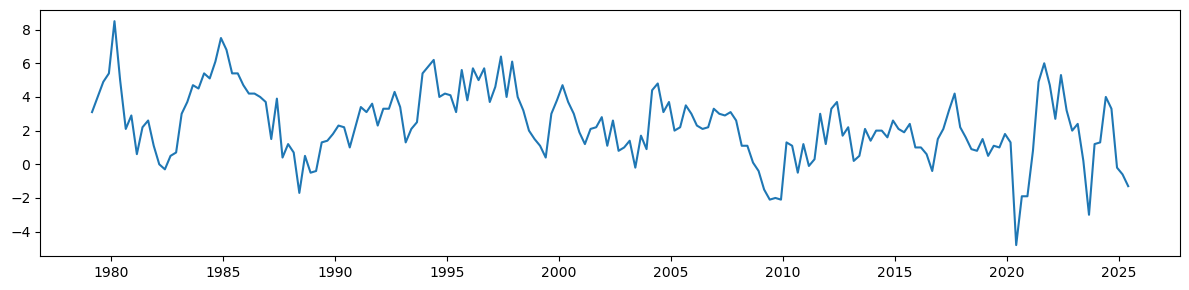

In [157]:
fig, ax = plt.subplots(figsize = (12, 3))
X = pd.to_numeric(qdf["CLV_PCH_SM"], errors= "coerce")
ax.plot(qdf.index, X, label = "GDP (% change)")
fig.tight_layout()
plt.show()

/opt/homebrew/Caskroom/miniconda/base/envs/py310/lib/python3.10/site-packages/statsmodels/graphics/tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


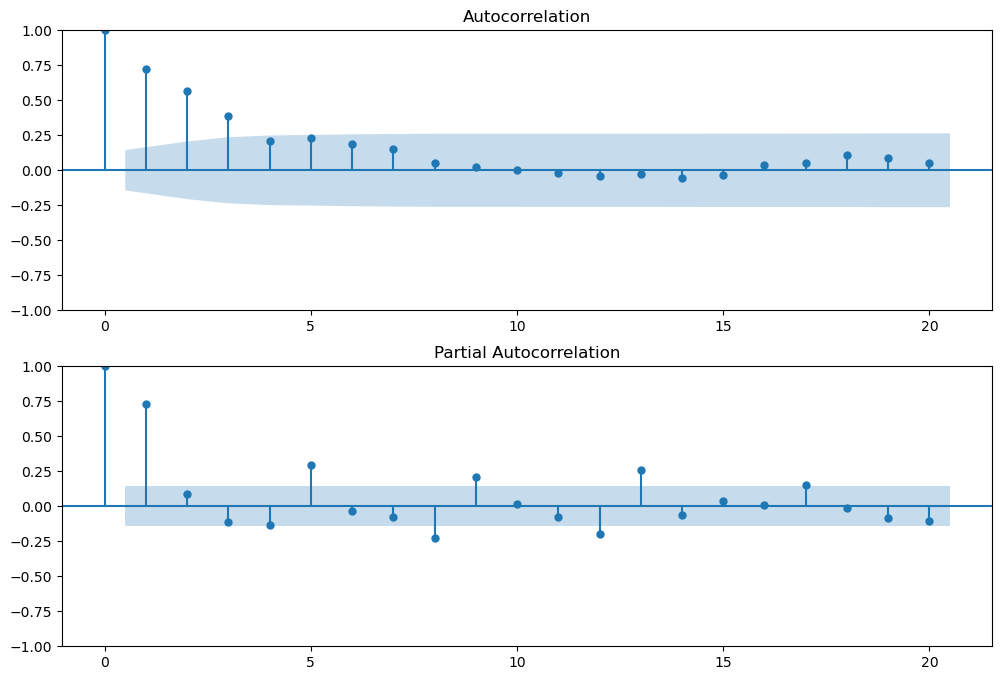

In [161]:
idxDrop = ~X.isna()
X = X.dropna()
fig = plt.figure(figsize=(12, 8))
ax1 = fig.add_subplot(211)
fig = sm.graphics.tsa.plot_acf(X, lags=20, ax=ax1)
ax2 = fig.add_subplot(212)
fig = sm.graphics.tsa.plot_pacf(X, lags=20, ax=ax2)

Another way of performing lag order selection is the use of -- as discussed in the lectures -- information criteria. 

This involves estimating a collection of candidate models and comparing a measure of their fit whilst penalising the number of parameters. 

Such model selection can be performed straightforwardly for ARMA models using statsmodels

In [ ]:
sm.tsa.arma_order_select_ic(X, ic = ["aicc", "bic"],
                             max_ar = 4, max_ma = 6,
                               fit_kw = {"method" : "innovations_mle"}
                               )


{'aic':             0           1           2           3           4           5  \
 0  805.316528  717.472395  691.820529  605.000958  603.746332  604.814647   
 1  665.053419  665.956219  653.640447  603.287889  603.769822  604.430243   
 2  665.592605  667.204919  640.123967  604.378595  604.666498  606.074039   
 3  665.464472  666.742231  624.376610  606.123539  606.666409  601.028276   
 4  663.079832  638.972009  625.976377  604.971886  604.453153  605.900512   
 
             6  
 0  606.703562  
 1  606.238865  
 2  607.919226  
 3  601.318292  
 4  602.579407  ,
 'bic':             0           1           2           3           4           5  \
 0  811.768021  727.149635  704.723515  621.129691  623.100812  627.394874   
 1  674.730659  678.859205  669.769181  622.642369  626.350048  630.236216   
 2  678.495591  683.333652  659.478447  626.958822  630.472471  635.105759   
 3  681.593205  686.096711  646.956836  631.929512  635.698129  633.285743   
 4  682.434312  661.552

The BIC penalises the number of parameters more strongly and so will generally favour models with fewer parameters.

 Here we will proceed with the ARMA(0, 3) = MA(3) model the BIC selects, which also appears to agree with inspection of the autocorrelation and partial autocorrelation plots.

In [131]:
# Estimation of ARMA(0, 3)  = ARIMA(0,0,3) = MA(3)

ma3 = sm.tsa.ARIMA(X, order = (0,0,3)).fit(method = "innovations_mle")
ma3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             CLV_PCH_SM   No. Observations:                  186
Model:                 ARIMA(0, 0, 3)   Log Likelihood                -297.500
Date:                Wed, 12 Nov 2025   AIC                            605.001
Time:                        14:28:44   BIC                            621.130
Sample:                    03-01-1979   HQIC                           611.537
                         - 06-01-2025                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.3762      0.352      6.747      0.000       1.686       3.067
ma.L1          0.9547      1.994      0.479      0.632      -2.954       4.863
ma.L2          0.9544      1.178      0.810      0.418      -1.355       3.264
ma.L3          0.9995      2.295      0.435      0.663      -3.499       5.498
sigma2         1.3393      3.092      0.433      0.665      -4.721       7.399
===================================================================================
Ljung-Box (L1) (Q):                   3.45   Jarque-Bera (JB):                65.15
Prob(Q):                              0.06   Prob(JB):                         0.00
Heteroskedasticity (H):               1.55   Skew:                            -0.40
Prob(H) (two-sided):                  0.09   Kurtosis:                         5.79
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [142]:
# We can directly use this to forecast the next observation:

X.index.freq = 'QS-DEC'
h=8
# fcst = ma3.get_forecast(steps = h)                            # Out of sample forecast
fcst = ma3.get_prediction(end = X.last_valid_index() + h * X.index.freq)       # In sample fit & out of sample forecast


In [179]:
df = qdf.loc[:, ["CLV_PCH_SM"]]
df = pd.concat([df, fcst.predicted_mean, fcst.conf_int()], axis = 1)
df.rename(columns={"CLV_PCH_SM" : "GDP growth",
                    "lower CLV_PCH_SM" : "lower ci",
                    "upper CLV_PCH_SM" : "upper ci"}, inplace=True)

df = df[df.index >= X.index[0]]
df["GDP growth"] = df["GDP growth"].map(lambda x: np.nan if x == ":" else float(x))

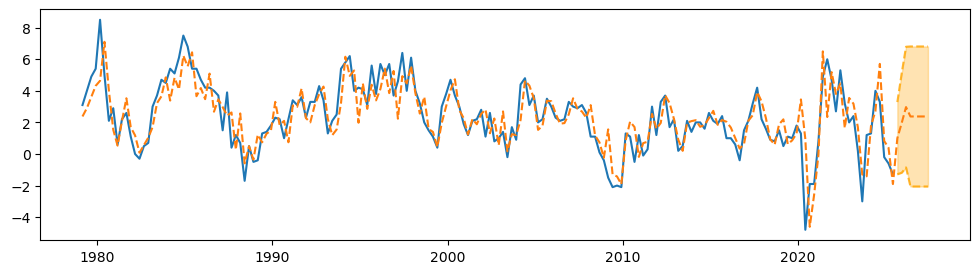

In [181]:
CI_insample = False    # change to True to have CI plotted over whole sample

if CI_insample:
    CI_ind = df.index
else:
    CI_ind = df.index[-h:]



fig, ax = plt.subplots(figsize = (12, 3))
ax.plot(df.index, df.iloc[:, 0])
ax.plot(df.index, df.iloc[:, 1], linestyle = "--")

ax.plot(CI_ind, df.loc[CI_ind, "lower ci"], color = "orange", alpha = 0.8, linestyle = "--")
ax.plot(CI_ind, df.loc[CI_ind, "upper ci"], color = "orange", alpha = 0.8, linestyle = "--")
ax.fill_between(CI_ind, df.loc[CI_ind, "lower ci"], df.loc[CI_ind, "upper ci"], color = "orange", alpha = 0.3)
plt.show()